## **DATA PREPARATION AND EXPLORATORY ANALYSIS**


## Initial Imports


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print(pd.__version__, np.__version__, matplotlib.__version__, sns.__version__, sklearn.__version__) # type: ignore

2.2.3 2.4.6 3.10.0 0.13.2 1.6.1


In [4]:
url = "https://raw.githubusercontent.com/malikbennett/aai4001-household-power-forecast/main/data/household_power_consumption.zip"
df = pd.read_csv(url, compression='zip', sep=';', na_values=['nan','?'])

In [5]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [78]:
df.shape

(2075259, 9)

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


In [80]:
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [81]:
print(df.isnull().sum())


Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [82]:
print(df.isnull().mean() * 100)

Date                     0.000000
Time                     0.000000
Global_active_power      1.251844
Global_reactive_power    1.251844
Voltage                  1.251844
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64


In [83]:
df.duplicated().sum()

np.int64(0)

**Commentary:**
The dataset contains 913,884 observations across 9 columns. Seven of them are numerical measurements stored as float64, while Date and Time are stored as object types, not datetime. They will need to be parsed into a proper datetime format before any time-based analysis can be done reliably.

Each of the seven measurement columns has 3,948 missing values (0.432% of records), the Time column has one missing value, and the Date column is complete. No duplicate records were found. Even though the share of missing data is small, it must be addressed before modelling: most algorithms cannot handle null values and will either fail or silently drop the affected rows, which can break the continuity of a time series and bias the results. Because all seven columns have the same number of gaps, they likely occur in the same rows, which points to whole-record outages in data collection rather than isolated sensor faults. This should be checked before choosing between removing the rows and imputing them.

Global Active Power averages approximately 1.091 kW and Voltage approximately 239.84 V. The sub-metering columns have low averages compared with their maximum values, which suggests intermittent consumption: long stretches of low use interrupted by occasional high-demand events. Dispersion varies across the measurements, so the variables sit on different scales and may need scaling or normalisation for some models. Some maximum values also suggest potential outliers. These have not been removed or treated, and they need further investigation to determine whether they reflect genuine peak usage or measurement errors.


Exploratory Data Analysis


In [84]:
df[df["Time"].isnull()]

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3


In [85]:
df = df.dropna(subset=["Time"])

In [86]:
df.shape

(2075259, 9)

In [87]:
df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

In [88]:
df = df.dropna(subset=["Time"]).copy()

In [89]:
df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

In [90]:
df[["Date", "Time", "DateTime"]].head()

,Date,Time,DateTime
0,16/12/2006,17:24:00,2006-12-16 17:24:00
1,16/12/2006,17:25:00,2006-12-16 17:25:00
2,16/12/2006,17:26:00,2006-12-16 17:26:00
3,16/12/2006,17:27:00,2006-12-16 17:27:00
4,16/12/2006,17:28:00,2006-12-16 17:28:00


In [91]:
df = df.sort_values("DateTime")

In [92]:
df[["DateTime", "Global_active_power"]].head()

,DateTime,Global_active_power
0,2006-12-16 17:24:00,4.216
1,2006-12-16 17:25:00,5.360
2,2006-12-16 17:26:00,5.374
3,2006-12-16 17:27:00,5.388
4,2006-12-16 17:28:00,3.666


In [93]:
df[["DateTime", "Global_active_power"]].tail()

,DateTime,Global_active_power
2075254,2010-11-26 20:58:00,0.946
2075255,2010-11-26 20:59:00,0.944
2075256,2010-11-26 21:00:00,0.938
2075257,2010-11-26 21:01:00,0.934
2075258,2010-11-26 21:02:00,0.932


In [94]:
df = df.set_index("DateTime")

In [95]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [96]:
hourly_df = df.select_dtypes(include="number").resample("h").mean()

In [97]:
hourly_df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667


In [98]:
hourly_df.shape

(34589, 7)

In [99]:
hourly_df.isnull().sum()

,0
Global_active_power,421
Global_reactive_power,421
Voltage,421
Global_intensity,421
Sub_metering_1,421
Sub_metering_2,421
Sub_metering_3,421


Histogram


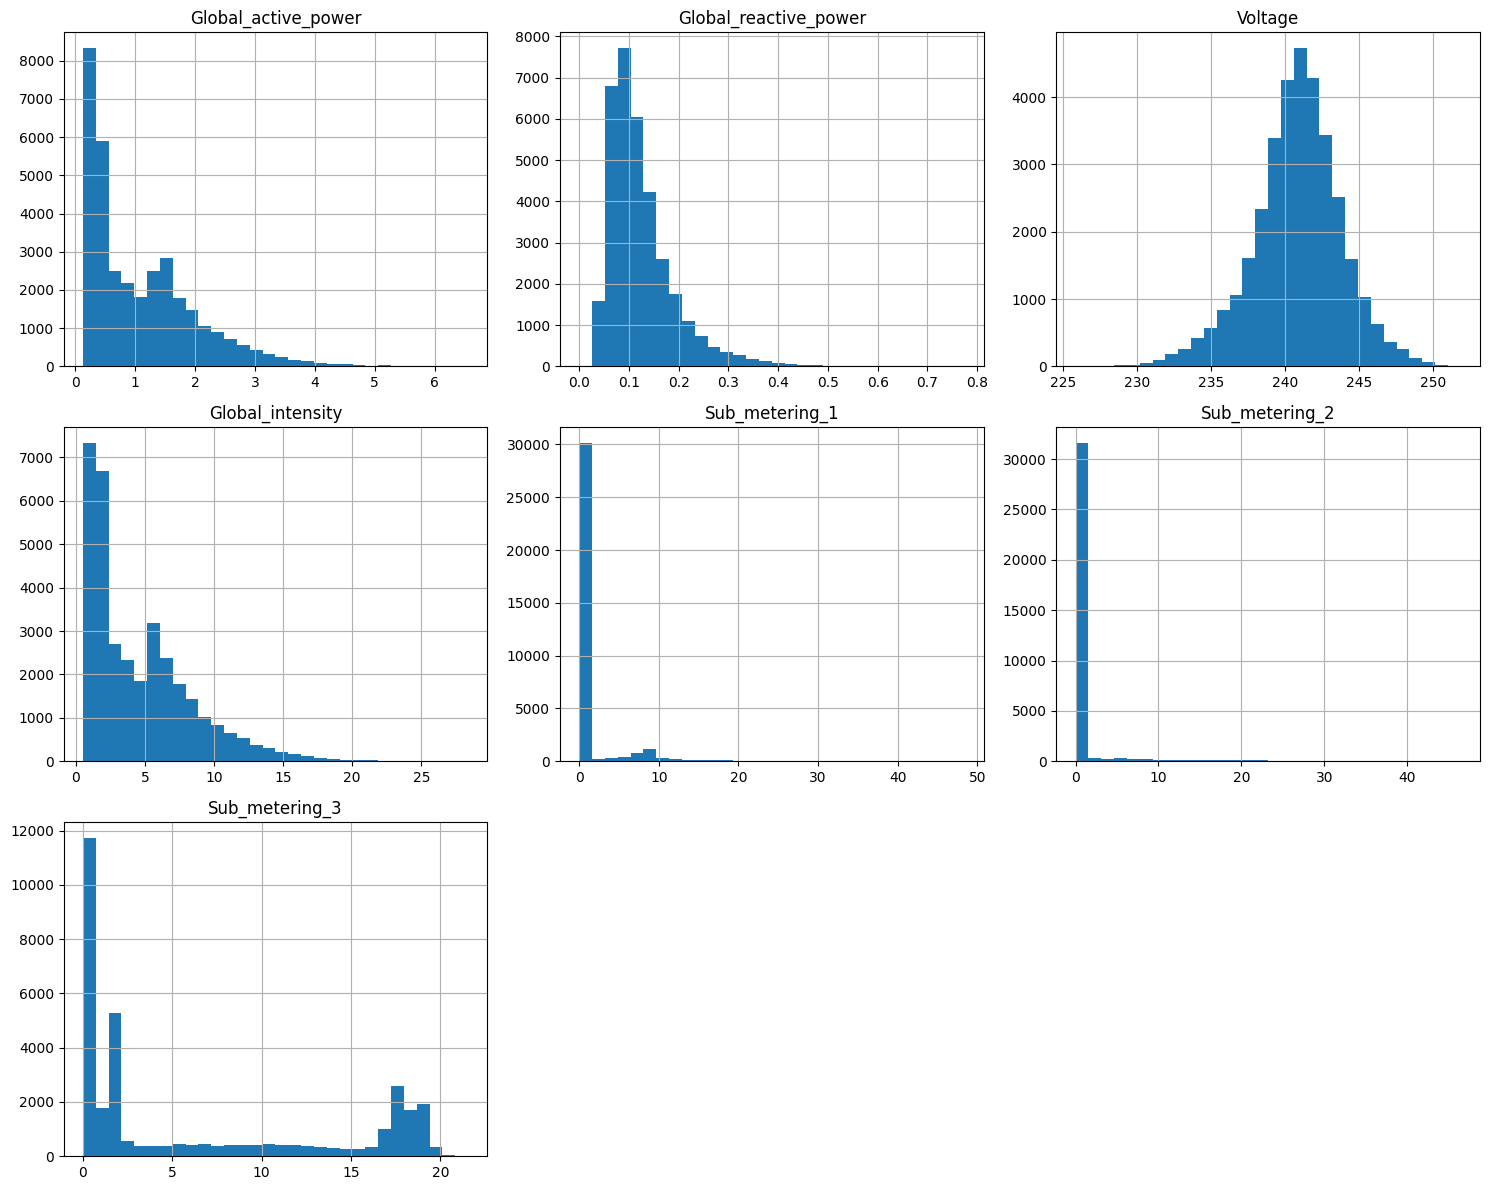

In [100]:


hourly_df.hist(figsize=(15, 12), bins=30)

plt.tight_layout()
plt.show()

In [101]:
hourly_df.skew()

,0
Global_active_power,1.297565
Global_reactive_power,1.873608
Voltage,-0.323136
Global_intensity,1.350666
Sub_metering_1,4.259900
Sub_metering_2,5.270892
Sub_metering_3,0.711388


In [102]:
hourly_df.describe().loc[["mean", "50%"]]

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
mean,1.091728,0.123727,240.839393,4.628238,1.121631,1.298566,6.458882
50%,0.802850,0.106917,240.977833,3.423333,0.000000,0.333333,1.650000


**Interpretation:**


Boxplot


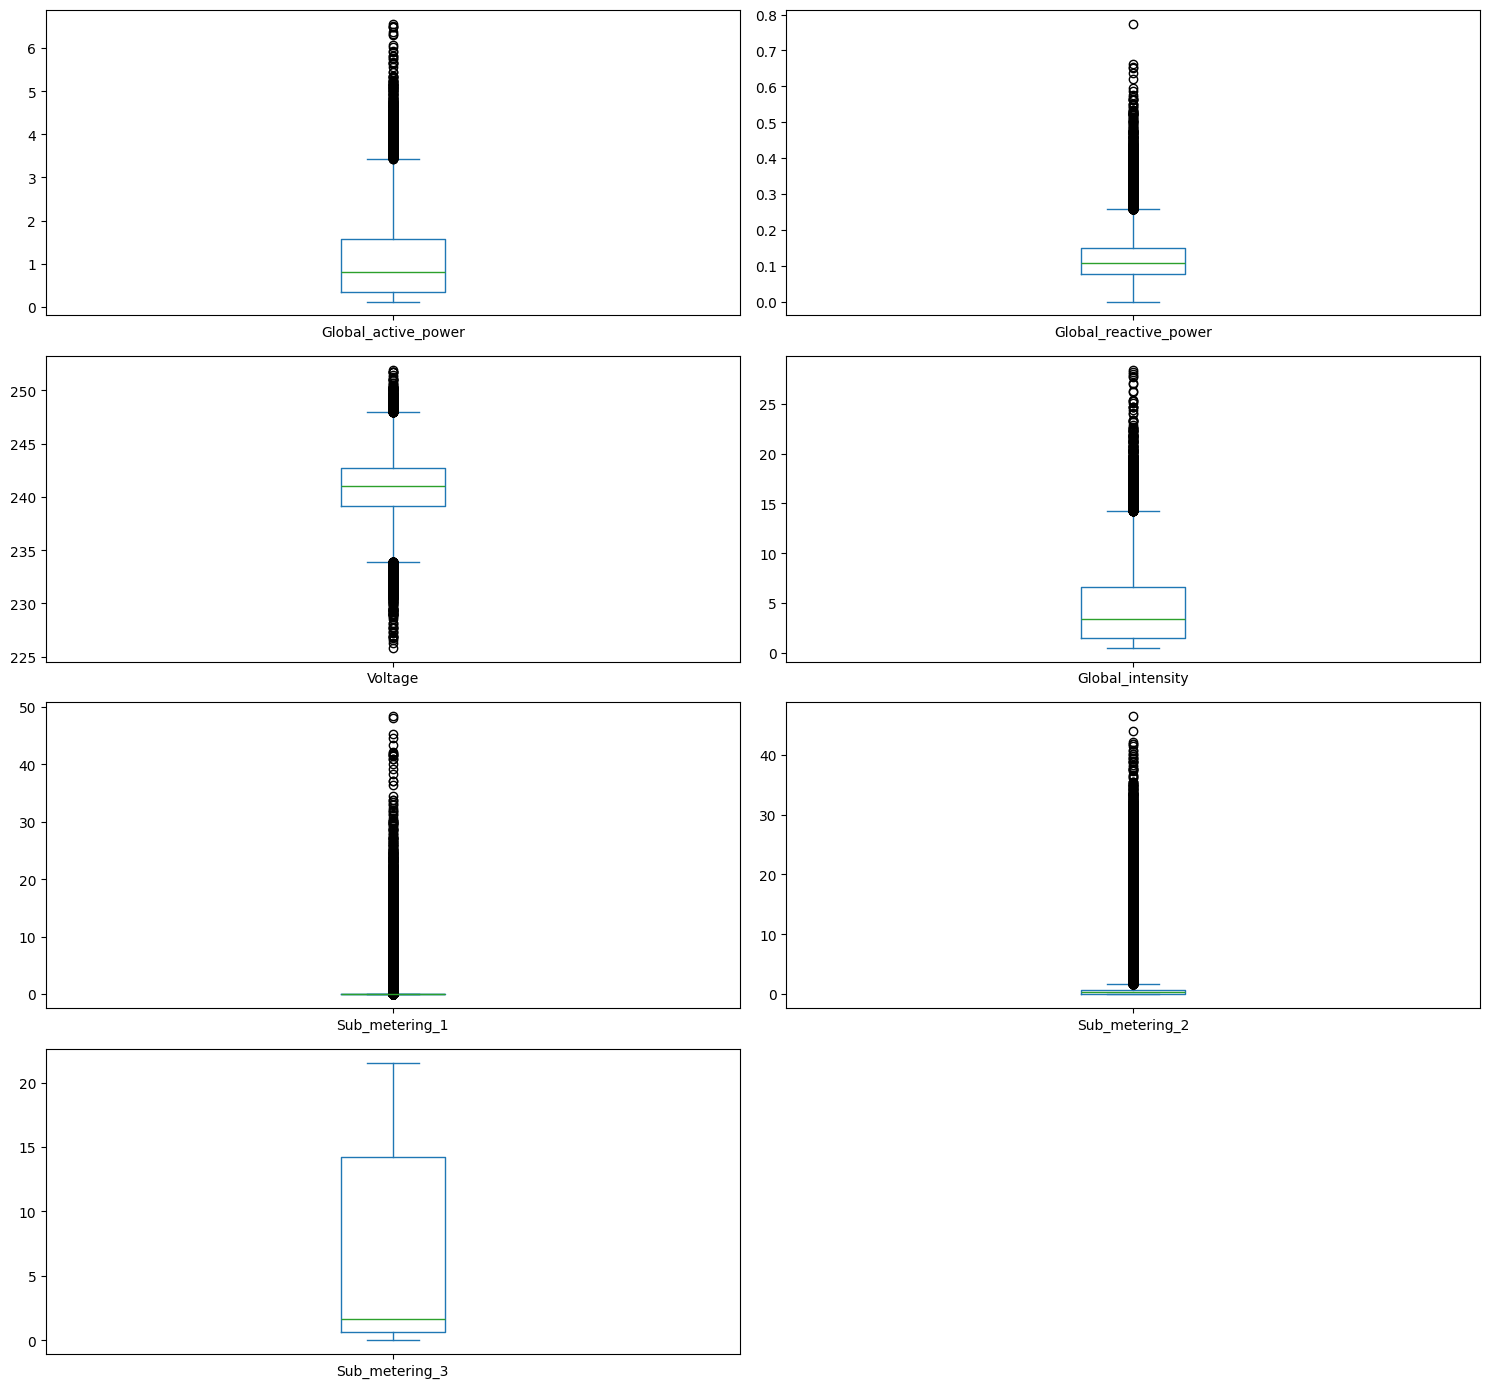

In [103]:
hourly_df.plot(
    kind="box",
    subplots=True,
    layout=(4, 2),
    figsize=(15, 14),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

In [104]:
Q1 = hourly_df.quantile(0.25)
Q3 = hourly_df.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (
    (hourly_df < lower_bound) |
    (hourly_df > upper_bound)
).sum()

outliers

,0
Global_active_power,733
Global_reactive_power,1647
Voltage,1077
Global_intensity,812
Sub_metering_1,4937
Sub_metering_2,2564
Sub_metering_3,0


In [105]:
(outliers / len(hourly_df) * 100).round(2)

,0
Global_active_power,2.12
Global_reactive_power,4.76
Voltage,3.11
Global_intensity,2.35
Sub_metering_1,14.27
Sub_metering_2,7.41
Sub_metering_3,0.00


**Interpretation:**


Correlation heatmap


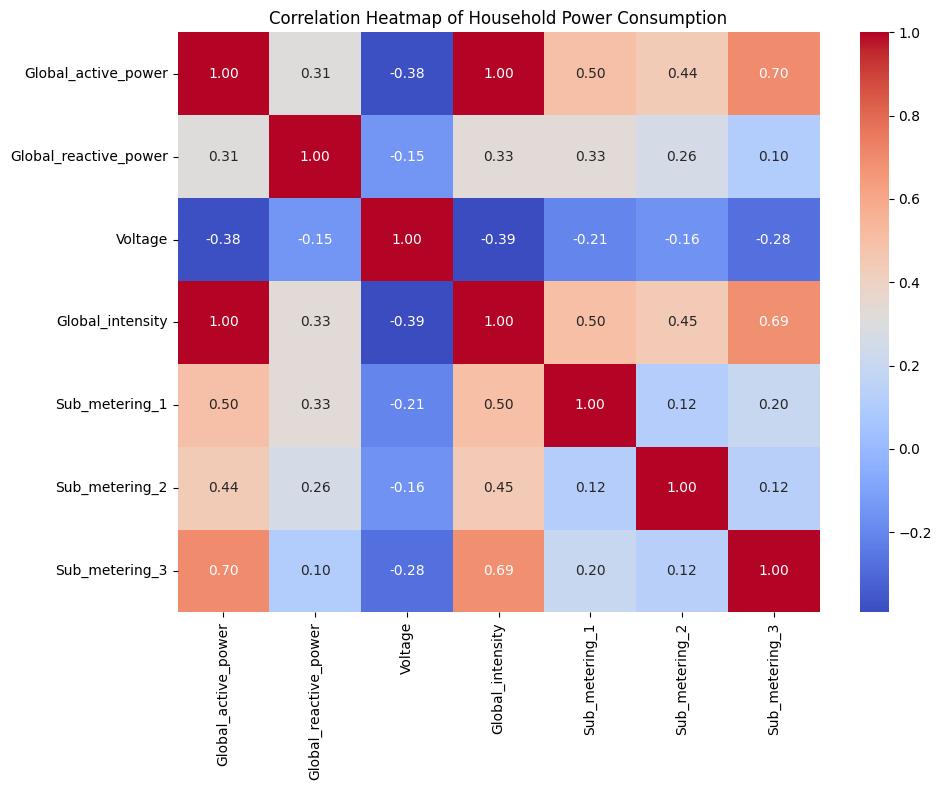

In [106]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = hourly_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Household Power Consumption")
plt.tight_layout()
plt.show()

In [107]:
correlation_matrix.loc[
    "Global_active_power",
    "Global_intensity"
]

np.float64(0.999422990563702)

**Interpretation:**


Time series Plot


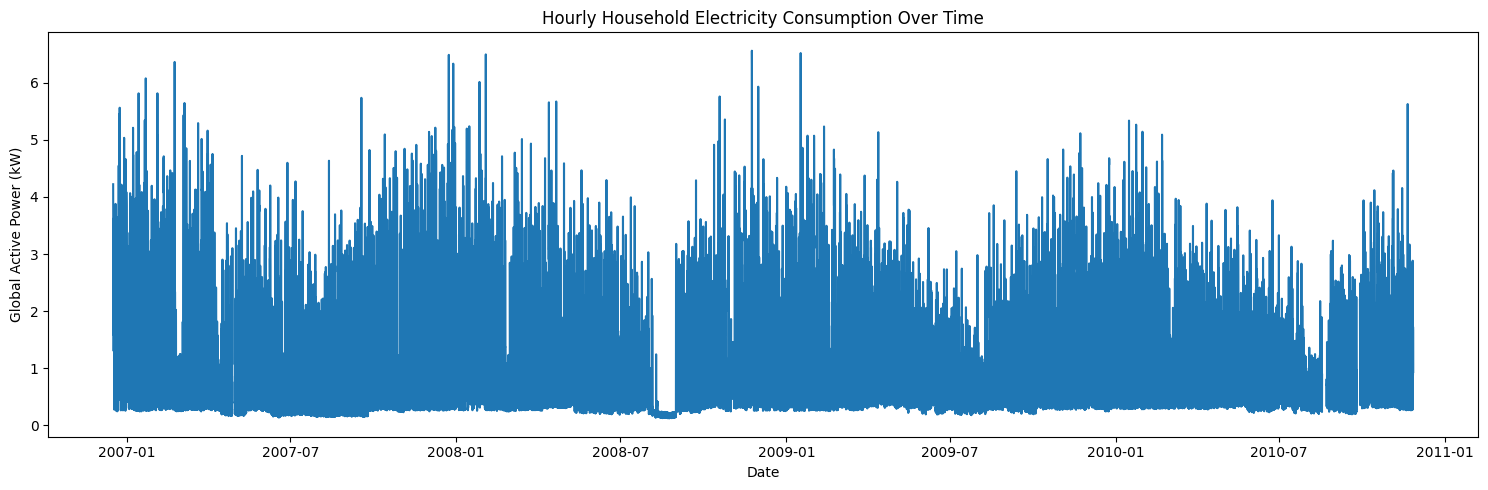

In [108]:
plt.figure(figsize=(15, 5))

plt.plot(
    hourly_df.index,
    hourly_df["Global_active_power"]
)

plt.title("Hourly Household Electricity Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.tight_layout()
plt.show()

In [109]:
monthly_consumption = hourly_df["Global_active_power"].resample("ME").mean()

monthly_consumption.head(10)

,Global_active_power
DateTime,
2006-12-31,1.903952
2007-01-31,1.546102
2007-02-28,1.401188
2007-03-31,1.318605
2007-04-30,0.890968
2007-05-31,0.985862
2007-06-30,0.827568
2007-07-31,0.667508
2007-08-31,0.764335


In [110]:
monthly_consumption.describe()

,Global_active_power
count,48.000000
mean,1.099445
std,0.299316
min,0.276557
25%,0.966234
50%,1.122891
75%,1.280951
max,1.903952


In [111]:
monthly_consumption.tail(12)

,Global_active_power
DateTime,
2009-12-31,1.364470
2010-01-31,1.430864
2010-02-28,1.375850
2010-03-31,1.129811
2010-04-30,1.027284
2010-05-31,1.095302
2010-06-30,0.969624
2010-07-31,0.721072
2010-08-31,0.591328


In [112]:
hourly_df["Global_active_power"].resample("ME").count().tail(3)

,Global_active_power
DateTime,
2010-09-30,633
2010-10-31,744
2010-11-30,622


**Interpretation:**


**Data Cleaning**


In [113]:
# Check the number of missing values in each column
hourly_df.isnull().sum()

,0
Global_active_power,421
Global_reactive_power,421
Voltage,421
Global_intensity,421
Sub_metering_1,421
Sub_metering_2,421
Sub_metering_3,421


In [114]:
# Display the timestamps where Global_active_power is missing
hourly_df[hourly_df["Global_active_power"].isnull()]

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,
2007-04-28 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-04-28 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-04-28 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-04-28 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-04-28 05:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
2010-09-28 14:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-09-28 15:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-09-28 16:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [115]:
# Identify consecutive periods with missing observations
missing_times = hourly_df.index[
    hourly_df["Global_active_power"].isnull()
]

missing_gaps = missing_times.to_series().diff()

print("Missing timestamps:", len(missing_times))
print("Time differences between missing timestamps:")
print(missing_gaps.value_counts())

Missing timestamps: 421
Time differences between missing timestamps:
DateTime
0 days 01:00:00      413
76 days 04:00:00       1
698 days 08:00:00      1
58 days 23:00:00       1
151 days 21:00:00      1
64 days 10:00:00       1
149 days 10:00:00      1
33 days 08:00:00       1
Name: count, dtype: int64


In [116]:
# Remove hourly observations with missing values
hourly_df = hourly_df.dropna().copy()

# Check the remaining missing values
hourly_df.isnull().sum()

,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0


In [117]:
hourly_df.shape

(34168, 7)

In [118]:
print("Remaining missing values:")
print(hourly_df.isnull().sum().sum())

print("Remaining duplicate rows:")
print(hourly_df.duplicated().sum())

Remaining missing values:
0
Remaining duplicate rows:
4


In [119]:
# Examine the minimum and maximum values
hourly_df.agg(["min", "max"]).T

,min,max
Global_active_power,0.124000,6.560533
Global_reactive_power,0.000000,0.774333
Voltage,225.834500,251.902000
Global_intensity,0.503333,28.383333
Sub_metering_1,0.000000,48.366667
Sub_metering_2,0.000000,46.433333
Sub_metering_3,0.000000,21.550000


In [120]:
# Count negative values in each numerical variable
(hourly_df < 0).sum()

,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0


**Commentary:**


**Feature Engineering and Preprocessing**


In [121]:
# Check the time differences between consecutive observations
hourly_df.index.to_series().diff().value_counts().head(10)

,count
DateTime,
0 days 01:00:00,34159
2 days 14:00:00,1
0 days 02:00:00,1
2 days 07:00:00,1
0 days 15:00:00,1
2 days 05:00:00,1
1 days 10:00:00,1
5 days 00:00:00,1
3 days 16:00:00,1


In [122]:
# Restore the complete hourly time index
full_hourly_index = pd.date_range(
    start=hourly_df.index.min(),
    end=hourly_df.index.max(),
    freq="h"
)

hourly_df = hourly_df.reindex(full_hourly_index)

hourly_df.index.name = "DateTime"

# Check missing values after restoring the timeline
hourly_df.isnull().sum()

,0
Global_active_power,421
Global_reactive_power,421
Voltage,421
Global_intensity,421
Sub_metering_1,421
Sub_metering_2,421
Sub_metering_3,421


In [123]:
hourly_df["Hour"] = hourly_df.index.hour

hourly_df[["Hour"]].head()

,Hour
DateTime,
2006-12-16 17:00:00,17
2006-12-16 18:00:00,18
2006-12-16 19:00:00,19
2006-12-16 20:00:00,20
2006-12-16 21:00:00,21


In [124]:
hourly_df["DayOfWeek"] = hourly_df.index.dayofweek

hourly_df[["DayOfWeek"]].head()

,DayOfWeek
DateTime,
2006-12-16 17:00:00,5
2006-12-16 18:00:00,5
2006-12-16 19:00:00,5
2006-12-16 20:00:00,5
2006-12-16 21:00:00,5


In [125]:
hourly_df["Month"] = hourly_df.index.month

hourly_df[["Month"]].head()

,Month
DateTime,
2006-12-16 17:00:00,12
2006-12-16 18:00:00,12
2006-12-16 19:00:00,12
2006-12-16 20:00:00,12
2006-12-16 21:00:00,12


In [126]:
hourly_df["IsWeekend"] = (
    hourly_df.index.dayofweek >= 5
).astype(int)

hourly_df[["IsWeekend"]].head()

,IsWeekend
DateTime,
2006-12-16 17:00:00,1
2006-12-16 18:00:00,1
2006-12-16 19:00:00,1
2006-12-16 20:00:00,1
2006-12-16 21:00:00,1


In [127]:
hourly_df[
    ["Hour", "DayOfWeek", "Month", "IsWeekend"]
].head(10)

,Hour,DayOfWeek,Month,IsWeekend
DateTime,,,,
2006-12-16 17:00:00,17,5,12,1
2006-12-16 18:00:00,18,5,12,1
2006-12-16 19:00:00,19,5,12,1
2006-12-16 20:00:00,20,5,12,1
2006-12-16 21:00:00,21,5,12,1
2006-12-16 22:00:00,22,5,12,1
2006-12-16 23:00:00,23,5,12,1
2006-12-17 00:00:00,0,6,12,1
2006-12-17 01:00:00,1,6,12,1


In [128]:
for lag in range(1, 25):
    hourly_df[f"Lag_{lag}"] = (
        hourly_df["Global_active_power"].shift(lag)
    )

lag_columns = [f"Lag_{i}" for i in range(1, 25)]

display(
    hourly_df[
        ["Global_active_power"] + lag_columns
    ].head(30)
)

,Global_active_power,Lag_1,Lag_2,Lag_3,Lag_4,Lag_5,Lag_6,Lag_7,Lag_8,Lag_9,...,Lag_15,Lag_16,Lag_17,Lag_18,Lag_19,Lag_20,Lag_21,Lag_22,Lag_23,Lag_24
DateTime,,,,,,,,,,,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,4.222889,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-16 19:00:00,3.400233,3.632200,4.222889,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-16 20:00:00,3.268567,3.400233,3.632200,4.222889,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-16 21:00:00,3.056467,3.268567,3.400233,3.632200,4.222889,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-16 22:00:00,2.200133,3.056467,3.268567,3.400233,3.632200,4.222889,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-16 23:00:00,2.061600,2.200133,3.056467,3.268567,3.400233,3.632200,4.222889,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-17 00:00:00,1.882467,2.061600,2.200133,3.056467,3.268567,3.400233,3.632200,4.222889,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-17 01:00:00,3.349400,1.882467,2.061600,2.200133,3.056467,3.268567,3.400233,3.632200,4.222889,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [129]:
print("Number of lag features:",
      len(lag_columns))

print("\nMissing values in each lag:")
print(hourly_df[lag_columns].isnull().sum())

Number of lag features: 24

Missing values in each lag:
Lag_1     422
Lag_2     423
Lag_3     424
Lag_4     425
Lag_5     426
Lag_6     427
Lag_7     428
Lag_8     429
Lag_9     430
Lag_10    431
Lag_11    432
Lag_12    433
Lag_13    434
Lag_14    435
Lag_15    436
Lag_16    437
Lag_17    438
Lag_18    439
Lag_19    440
Lag_20    441
Lag_21    442
Lag_22    443
Lag_23    444
Lag_24    445
dtype: int64


Interpretation:


**Feature Engineering and Preprocessing**


In [130]:
for window in [3, 6, 12, 24]:
    hourly_df[f"Rolling_Mean_{window}"] = (
        hourly_df["Global_active_power"]
        .shift(1)
        .rolling(window=window)
        .mean()
    )

In [131]:
rolling_columns = [
    "Rolling_Mean_3",
    "Rolling_Mean_6",
    "Rolling_Mean_12",
    "Rolling_Mean_24"
]

display(
    hourly_df[
        ["Global_active_power"] + rolling_columns
    ].head(30)
)

,Global_active_power,Rolling_Mean_3,Rolling_Mean_6,Rolling_Mean_12,Rolling_Mean_24
DateTime,,,,,
2006-12-16 17:00:00,4.222889,NaN,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,NaN,NaN,NaN,NaN
2006-12-16 19:00:00,3.400233,NaN,NaN,NaN,NaN
2006-12-16 20:00:00,3.268567,3.751774,NaN,NaN,NaN
2006-12-16 21:00:00,3.056467,3.433667,NaN,NaN,NaN
2006-12-16 22:00:00,2.200133,3.241756,NaN,NaN,NaN
2006-12-16 23:00:00,2.061600,2.841722,3.296748,NaN,NaN
2006-12-17 00:00:00,1.882467,2.439400,2.936533,NaN,NaN
2006-12-17 01:00:00,3.349400,2.048067,2.644911,NaN,NaN


In [132]:
for window in [3, 6, 12, 24]:
    hourly_df[f"Rolling_Std_{window}"] = (
        hourly_df["Global_active_power"]
        .shift(1)
        .rolling(window=window)
        .std()
    )

In [133]:
rolling_std_columns = [
    "Rolling_Std_3",
    "Rolling_Std_6",
    "Rolling_Std_12",
    "Rolling_Std_24"
]

display(
    hourly_df[
        ["Global_active_power"] + rolling_std_columns
    ].head(30)
)

,Global_active_power,Rolling_Std_3,Rolling_Std_6,Rolling_Std_12,Rolling_Std_24
DateTime,,,,,
2006-12-16 17:00:00,4.222889,NaN,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,NaN,NaN,NaN,NaN
2006-12-16 19:00:00,3.400233,NaN,NaN,NaN,NaN
2006-12-16 20:00:00,3.268567,0.424163,NaN,NaN,NaN
2006-12-16 21:00:00,3.056467,0.184108,NaN,NaN,NaN
2006-12-16 22:00:00,2.200133,0.173445,NaN,NaN,NaN
2006-12-16 23:00:00,2.061600,0.565662,0.669637,NaN,NaN
2006-12-17 00:00:00,1.882467,0.538866,0.652900,NaN,NaN
2006-12-17 01:00:00,3.349400,0.159265,0.670557,NaN,NaN


In [134]:
print("Dataset shape:", hourly_df.shape)

print("\nMissing values in each column:")
print(hourly_df.isnull().sum())

Dataset shape: (34589, 43)

Missing values in each column:
Global_active_power      421
Global_reactive_power    421
Voltage                  421
Global_intensity         421
Sub_metering_1           421
Sub_metering_2           421
Sub_metering_3           421
Hour                       0
DayOfWeek                  0
Month                      0
IsWeekend                  0
Lag_1                    422
Lag_2                    423
Lag_3                    424
Lag_4                    425
Lag_5                    426
Lag_6                    427
Lag_7                    428
Lag_8                    429
Lag_9                    430
Lag_10                   431
Lag_11                   432
Lag_12                   433
Lag_13                   434
Lag_14                   435
Lag_15                   436
Lag_16                   437
Lag_17                   438
Lag_18                   439
Lag_19                   440
Lag_20                   441
Lag_21                   442
Lag_22       

In [135]:
missing_times = hourly_df.index[
    hourly_df["Global_active_power"].isna()
]

missing_series = pd.Series(missing_times, index=missing_times)

groups = missing_series.diff().ne(
    pd.Timedelta(hours=1)
).cumsum()

print("Missing hourly records:", len(missing_times))
print("\nMissing time intervals:")

for _, group in missing_series.groupby(groups):
    print(
        group.iloc[0],
        "to",
        group.iloc[-1],
        "| Hours:",
        len(group)
    )

Missing hourly records: 421

Missing time intervals:
2007-04-28 01:00:00 to 2007-04-30 13:00:00 | Hours: 61
2007-07-15 17:00:00 to 2007-07-15 17:00:00 | Hours: 1
2009-06-13 01:00:00 to 2009-06-15 06:00:00 | Hours: 54
2009-08-13 05:00:00 to 2009-08-13 18:00:00 | Hours: 14
2010-01-12 15:00:00 to 2010-01-14 18:00:00 | Hours: 52
2010-03-20 04:00:00 to 2010-03-21 12:00:00 | Hours: 33
2010-08-17 22:00:00 to 2010-08-22 20:00:00 | Hours: 119
2010-09-25 04:00:00 to 2010-09-28 18:00:00 | Hours: 87


In [136]:
# Interpolate the isolated missing hour
hourly_df = hourly_df.interpolate(
    method="time",
    limit=1,
    limit_area="inside"
)

# Remove rows that still contain missing original measurements
measurement_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

hourly_df = hourly_df.dropna(
    subset=measurement_columns
).copy()

print("Dataset shape:", hourly_df.shape)

print("\nMissing values in original measurements:")
print(hourly_df[measurement_columns].isnull().sum())

Dataset shape: (34176, 43)

Missing values in original measurements:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [137]:
# Recreate the complete hourly timeline
full_index = pd.date_range(
    start=hourly_df.index.min(),
    end=hourly_df.index.max(),
    freq="h"
)

# Restore missing hours in the timeline
target_full = hourly_df["Global_active_power"].reindex(full_index)

# Recalculate lag features
for lag in range(1, 25):
    hourly_df[f"Lag_{lag}"] = (
        target_full.shift(lag).reindex(hourly_df.index)
    )

# Recalculate rolling means and standard deviations
for window in [3, 6, 12, 24]:

    hourly_df[f"Rolling_Mean_{window}"] = (
        target_full.shift(1)
        .rolling(window=window)
        .mean()
        .reindex(hourly_df.index)
    )

    hourly_df[f"Rolling_Std_{window}"] = (
        target_full.shift(1)
        .rolling(window=window)
        .std()
        .reindex(hourly_df.index)
    )

print("Updated dataset shape:", hourly_df.shape)

print("\nMissing values in engineered features:")
engineered_columns = (
    [f"Lag_{i}" for i in range(1, 25)]
    + [f"Rolling_Mean_{i}" for i in [3, 6, 12, 24]]
    + [f"Rolling_Std_{i}" for i in [3, 6, 12, 24]]
)

print(hourly_df[engineered_columns].isnull().sum())

Updated dataset shape: (34176, 43)

Missing values in engineered features:
Lag_1                8
Lag_2               16
Lag_3               24
Lag_4               32
Lag_5               40
Lag_6               48
Lag_7               56
Lag_8               64
Lag_9               72
Lag_10              80
Lag_11              88
Lag_12              96
Lag_13             104
Lag_14             111
Lag_15             118
Lag_16             125
Lag_17             132
Lag_18             139
Lag_19             146
Lag_20             153
Lag_21             160
Lag_22             167
Lag_23             174
Lag_24             181
Rolling_Mean_3      24
Rolling_Mean_6      48
Rolling_Mean_12     96
Rolling_Mean_24    192
Rolling_Std_3       24
Rolling_Std_6       48
Rolling_Std_12      96
Rolling_Std_24     192
dtype: int64


In [138]:
# Remove rows with incomplete lag and rolling features
hourly_df = hourly_df.dropna(
    subset=engineered_columns
).copy()

print("Final dataset shape:", hourly_df.shape)

print("\nRemaining missing values:")
print(hourly_df.isnull().sum())

print("\nDuplicate timestamps:", hourly_df.index.duplicated().sum())

print("\nChronological order:", hourly_df.index.is_monotonic_increasing)

Final dataset shape: (33984, 43)

Remaining missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
Hour                     0
DayOfWeek                0
Month                    0
IsWeekend                0
Lag_1                    0
Lag_2                    0
Lag_3                    0
Lag_4                    0
Lag_5                    0
Lag_6                    0
Lag_7                    0
Lag_8                    0
Lag_9                    0
Lag_10                   0
Lag_11                   0
Lag_12                   0
Lag_13                   0
Lag_14                   0
Lag_15                   0
Lag_16                   0
Lag_17                   0
Lag_18                   0
Lag_19                   0
Lag_20                   0
Lag_21                   0
Lag_22                   0
Lag_23                   0
Lag_24                

In [139]:
# Define the target variable
y = hourly_df["Global_active_power"]

# Define the predictor variables
feature_columns = (
    ["Hour", "DayOfWeek", "Month", "IsWeekend"]
    + [f"Lag_{i}" for i in range(1, 25)]
    + [f"Rolling_Mean_{i}" for i in [3, 6, 12, 24]]
    + [f"Rolling_Std_{i}" for i in [3, 6, 12, 24]]
)

X = hourly_df[feature_columns]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget variable:", y.name)
print("\nNumber of predictor features:", len(feature_columns))

Feature dataset shape: (33984, 36)
Target dataset shape: (33984,)

Target variable: Global_active_power

Number of predictor features: 36


Interpretation:


**Train/Test Split**


In [140]:
# Determine the 80% training split point
split_index = int(len(X) * 0.80)

# Split the features
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

# Split the target
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting period:")
print(X_test.index.min(), "to", X_test.index.max())

Training features: (27187, 36)
Testing features: (6797, 36)

Training period:
2006-12-17 17:00:00 to 2010-02-03 20:00:00

Testing period:
2010-02-03 21:00:00 to 2010-11-26 21:00:00


Interpretation:


**Pipeline Construction:**


In [141]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify numerical features
numeric_features = feature_columns

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features)
    ]
)

# Create the preprocessing pipeline
preprocessing_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [142]:
# Fit on training data and transform it
X_train_processed = preprocessing_pipeline.fit_transform(X_train)

# Transform testing data without fitting again
X_test_processed = preprocessing_pipeline.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (27187, 36)
Processed testing shape: (6797, 36)


In [143]:
import pandas as pd

# Convert processed training data back to a DataFrame
X_train_scaled = pd.DataFrame(
    X_train_processed,
    columns=feature_columns,
    index=X_train.index
)

# Display the mean and standard deviation
print("Feature means after scaling:")
print(X_train_scaled.mean().round(3))

print("\nFeature standard deviations after scaling:")
print(X_train_scaled.std().round(3))

Feature means after scaling:
Hour               0.0
DayOfWeek          0.0
Month             -0.0
IsWeekend          0.0
Lag_1             -0.0
Lag_2              0.0
Lag_3             -0.0
Lag_4              0.0
Lag_5             -0.0
Lag_6             -0.0
Lag_7             -0.0
Lag_8              0.0
Lag_9             -0.0
Lag_10             0.0
Lag_11             0.0
Lag_12            -0.0
Lag_13            -0.0
Lag_14            -0.0
Lag_15             0.0
Lag_16            -0.0
Lag_17            -0.0
Lag_18            -0.0
Lag_19             0.0
Lag_20             0.0
Lag_21             0.0
Lag_22            -0.0
Lag_23            -0.0
Lag_24             0.0
Rolling_Mean_3    -0.0
Rolling_Mean_6    -0.0
Rolling_Mean_12    0.0
Rolling_Mean_24    0.0
Rolling_Std_3     -0.0
Rolling_Std_6      0.0
Rolling_Std_12     0.0
Rolling_Std_24    -0.0
dtype: float64

Feature standard deviations after scaling:
Hour               1.0
DayOfWeek          1.0
Month              1.0
IsWeekend      

In [144]:
# Save the final prepared dataset
hourly_df.to_csv(
    "final_household_power_dataset.csv",
    index=True
)

print("Dataset saved successfully!")

Dataset saved successfully!
